# B3_histogram: Evaluasi Praktikum P1-P4 Computer Vision (SIMUTEH)
**Nama:** Rian | **NIM:** 2330511025 | **SEED:** 1025 | **Kelas:** 6A

Membutuhkan dataset dari B1. Mengerjakan lembar hitung 3.1, diagnosis histogram, perbaikan citra, eksperimen CLAHE, serta P3.1 sampai P3.6.

> Angka pada teks jawaban berasal dari satu kali jalan dengan SEED 1025. Nilai KB dan PSNR deterministik; **waktu (ms)** bergantung mesin, jadi cocokkan dengan keluaran milikmu.

## Bagian 3. Histogram dan Perbaikan Citra

In [1]:
import os, sys
# Jalankan dari folder notebook/ di dalam repository (jalur file selalu diawali ../).
if os.path.basename(os.getcwd()) != "notebook":
    cand = "/content/simuteh-2330511025/notebook"
    if os.path.exists(cand): os.chdir(cand)
    else: raise SystemExit("Buka notebook ini dari folder notebook/ di repository (di Colab: git clone repo-mu dahulu, lalu %cd simuteh-2330511025/notebook).")
sys.path.append("../src")
import cv2, numpy as np, matplotlib.pyplot as plt, pandas as pd, time
from matplotlib.patches import FancyBboxPatch
from utils_cv import baca, tampil, kontras_bercak, statistik
if not os.path.exists("../data/sintetis/label.csv"):
    raise SystemExit("Dataset belum ada. Jalankan B1_lingkungan.ipynb dahulu (atau: cd .. lalu python src/buat_dataset_sintetis.py).")
URUT = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
label = pd.read_csv("../data/sintetis/label.csv")
print("Folder kerja:", os.getcwd(), "| citra:", len(label))

Folder kerja: /tmp/repo/simuteh-2330511025/notebook | citra: 60


### Langkah 3.1 Lembar hitung manual

Matriks M (3 bit, L = 8):
```
[[1,2,2,3],[2,2,3,3],[1,2,3,4],[2,3,3,2]]
```
**a) Histogram.** Jumlah piksel: r=1 → 2, r=2 → 7, r=3 → 6, r=4 → 1, lainnya 0 (total 16). Diagram batang: tinggi 2, 7, 6, 1 untuk r = 1, 2, 3, 4 (gambar dibuat pada sel kode di bawah).

**b) Peregangan kontras** ke 0..7 dengan rmin = 1 dan rmax = 4: $s = \mathrm{round}\big((r-1)/(4-1)\times 7\big)$. Hasil: 1→0, 2→2,33→**2**, 3→4,67→**5**, 4→7.
```
[[0,2,2,5],[2,2,5,5],[0,2,5,7],[2,5,5,2]]
```
**c) Ekualisasi** ($s = \mathrm{round}(7 \times \mathrm{CDF})$):

| r | n | PDF = n/16 | CDF | 7 x CDF | s |
|---|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 | 0 |
| 1 | 2 | 0,1250 | 0,1250 | 0,875 | 1 |
| 2 | 7 | 0,4375 | 0,5625 | 3,9375 | 4 |
| 3 | 6 | 0,3750 | 0,9375 | 6,5625 | 7 |
| 4 | 1 | 0,0625 | 1,0000 | 7,0 | 7 |
| 5 | 0 | 0 | 1,0 | 7,0 | 7 |
| 6 | 0 | 0 | 1,0 | 7,0 | 7 |
| 7 | 0 | 0 | 1,0 | 7,0 | 7 |

Pemetaan: 1→1, 2→4, 3→7, 4→7. Matriks hasil:
```
[[1,4,4,7],[4,4,7,7],[1,4,7,7],[4,7,7,4]]
```
**d) Operasi titik 8 bit.**
- Negatif r = 60: $255 - 60 = 195$.
- Kontras $s = 1{,}4r - 30$: untuk r = 120, $s = 168 - 30 = 138$; untuk r = 210, $s = 294 - 30 = 264$, di-*clip* menjadi **255**.
- Gamma r = 100: $s = 255\,(100/255)^{\gamma}$. Untuk γ = 0,6: $(0{,}3922)^{0{,}6} = 0{,}5703$, jadi $s \approx 145$ (mencerahkan). Untuk γ = 1,8: $(0{,}3922)^{1{,}8} = 0{,}1855$, jadi $s \approx 47$ (menggelapkan).

histogram: [0 2 7 6 1 0 0 0]
regang:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
s per r: [0 1 4 7 7 7 7 7]
ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
negatif 60: 195 | kontras 120: 138.0 | kontras 210: 255
gamma0.6: 145.4 | gamma1.8: 47.3


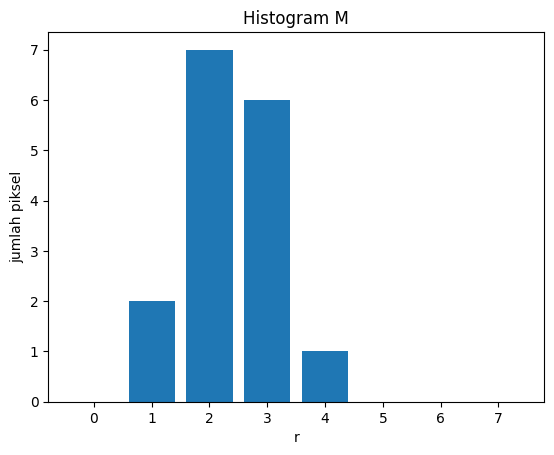

In [2]:
M = np.array([[1,2,2,3],[2,2,3,3],[1,2,3,4],[2,3,3,2]])
cnt = np.bincount(M.ravel(), minlength=8); cdf = np.cumsum(cnt)/16; s = np.round(7*cdf).astype(int)
print("histogram:", cnt); print("regang:\n", np.round((M-M.min())/(M.max()-M.min())*7).astype(int))
print("s per r:", s); print("ekualisasi:\n", s[M])
print("negatif 60:", 255-60, "| kontras 120:", 1.4*120-30, "| kontras 210:", min(255, 1.4*210-30))
print("gamma0.6:", round(255*(100/255)**0.6, 1), "| gamma1.8:", round(255*(100/255)**1.8, 1))
plt.bar(range(8), cnt); plt.xlabel("r"); plt.ylabel("jumlah piksel"); plt.title("Histogram M"); plt.savefig("../hasil/b3_hist_manual.png"); plt.show()

### Langkah 3.2 Diagnosis mutu (Kode 3.1) dan Tabel 9

teh_041.png {'rerata': 176.8, 'simpangan_baku': 36.5, 'min': 77, 'maks': 223, 'persen_gelap': 0.0, 'persen_terang': 4.0}
teh_042.png {'rerata': 117.0, 'simpangan_baku': 36.7, 'min': 8, 'maks': 177, 'persen_gelap': 9.2, 'persen_terang': 0.0}
teh_043.png {'rerata': 210.7, 'simpangan_baku': 27.8, 'min': 137, 'maks': 250, 'persen_gelap': 0.0, 'persen_terang': 75.7}
teh_044.png {'rerata': 154.8, 'simpangan_baku': 15.0, 'min': 98, 'maks': 195, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 132.2, 'simpangan_baku': 58.4, 'min': 24, 'maks': 250, 'persen_gelap': 1.7, 'persen_terang': 16.4}


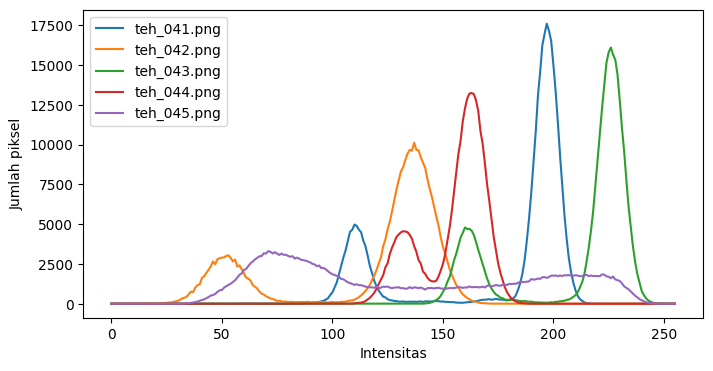


-- teh_021 sampai teh_025 (ringan) --
teh_021 {'rerata': 167.1, 'simpangan_baku': 33.5, 'min': 78, 'maks': 207, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_022 {'rerata': 126.6, 'simpangan_baku': 41.7, 'min': 14, 'maks': 187, 'persen_gelap': 12.4, 'persen_terang': 0.0}
teh_023 {'rerata': 215.5, 'simpangan_baku': 28.5, 'min': 128, 'maks': 255, 'persen_gelap': 0.0, 'persen_terang': 76.6}
teh_024 {'rerata': 154.2, 'simpangan_baku': 16.6, 'min': 99, 'maks': 197, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025 {'rerata': 126.7, 'simpangan_baku': 56.7, 'min': 26, 'maks': 249, 'persen_gelap': 1.6, 'persen_terang': 13.5}
rerata kelima citra ringan: {'rerata': 158.0, 'simpangan_baku': 35.4, 'min': 69.0, 'maks': 219.0, 'persen_gelap': 2.8, 'persen_terang': 18.0}


In [3]:
nama_list = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]
plt.figure(figsize=(8, 4))
for nm in nama_list:
    g_ = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    print(nm, statistik(g_))
    plt.plot(cv2.calcHist([g_], [0], None, [256], [0, 256]), label=nm)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend(); plt.savefig("../hasil/b3_histogram_5kondisi.png"); plt.show()
print("\n-- teh_021 sampai teh_025 (ringan) --")
st = [statistik(cv2.cvtColor(baca(f"../data/sintetis/citra/teh_{i:03d}.png"), cv2.COLOR_BGR2GRAY)) for i in range(21, 26)]
for i, x in zip(range(21, 26), st): print(f"teh_{i:03d}", x)
print("rerata kelima citra ringan:", pd.DataFrame(st).mean().round(1).to_dict())

**Tabel 9. Diagnosis mutu citra** (angka dari keluaran sel di atas)

| Citra | Rerata | Simp. baku | Min-maks | % gelap | % terang | Diagnosis | Usulan perbaikan |
|---|---|---|---|---|---|---|---|
| teh_041 (normal) | 176,8 | 36,5 | 77-223 | 0,0 | 4,0 | Pencahayaan dan kontras baik | Cukup penapis derau |
| teh_042 (gelap) | 117,0 | 36,7 | 8-177 | 9,2 | 0,0 | Histogram bergeser ke kiri, kontras sedang | Peregangan kontras (persentil 2 dan 98); pencerahan gamma < 1 diuji dan ternyata tidak menaikkan KB (Langkah 3.5) |
| teh_043 (terang) | 210,7 | 27,8 | 137-250 | 0,0 | 75,7 | Histogram menumpuk di kanan, banyak piksel hampir jenuh | Koreksi gamma > 1 (menggelapkan) |
| teh_044 (kontras rendah) | 154,8 | 15,0 | 98-195 | 0,0 | 0,0 | Histogram sempit di tengah | Peregangan kontras (persentil 2 dan 98) |
| teh_045 (bayangan) | 132,2 | 58,4 | 24-250 | 1,7 | 16,4 | Histogram dua puncak (sisi teduh dan sisi terang), simpangan baku terbesar | CLAHE (perbaikan lokal), bukan ekualisasi global |
| teh_021 sampai 025 (ringan, rata-rata) | 158,0 | 35,4 | 69-219 | 2,8 | 18,0 | Campuran kelima kondisi; statistik rata-rata tidak mewakili satu kondisi | Pilih perbaikan per kondisi (lihat P3.5) |

### Langkah 3.3 Perbaikan citra kondisi bayangan (Kode 3.2) dan Tabel 10

persentil 2 dan 98: 51.0 232.0
    Metode           Parameter   KB  Simpangan baku
      asli                   - 1.11            58.4
   negatif             255 - r 1.11            58.4
  cerah+50                 +50 1.11            54.7
   kontras alpha 1,5; beta -40 1.11            78.8
    regang      persentil 2-98 1.14            81.9
  gamma0.5           gamma 0,5 1.00            41.0
  gamma1.8           gamma 1,8 1.29            65.3
ekualisasi              global 0.90            73.5
     CLAHE      clip 2; tile 8 1.71            48.7


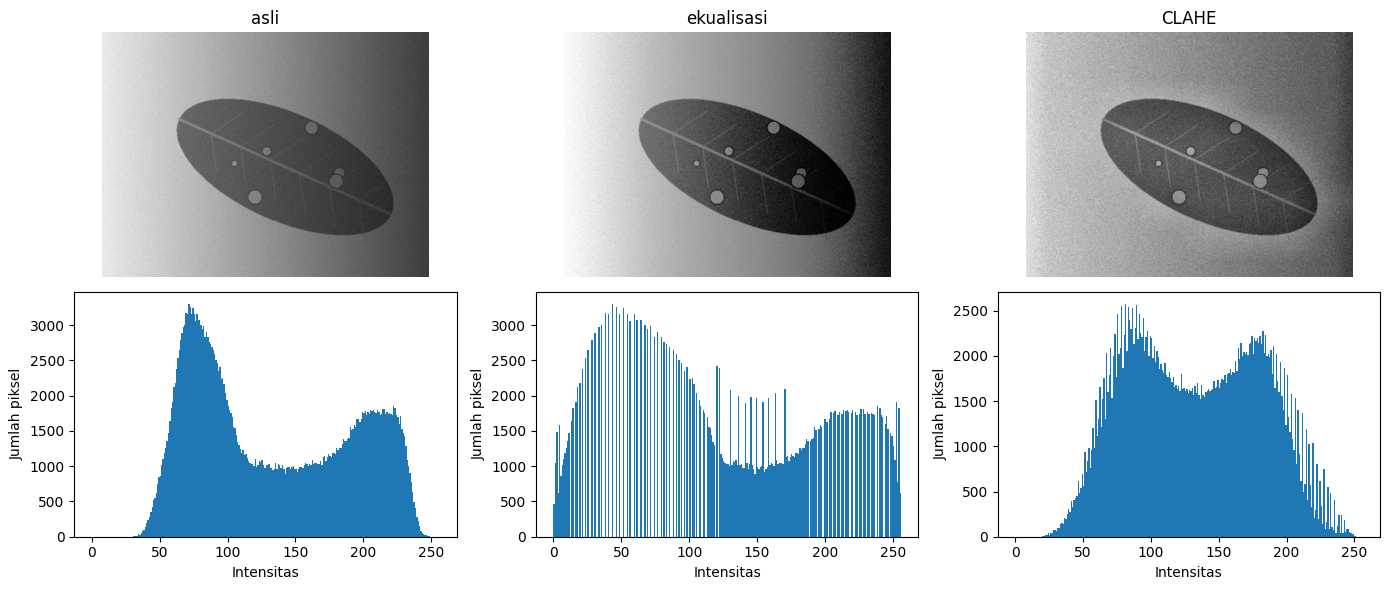

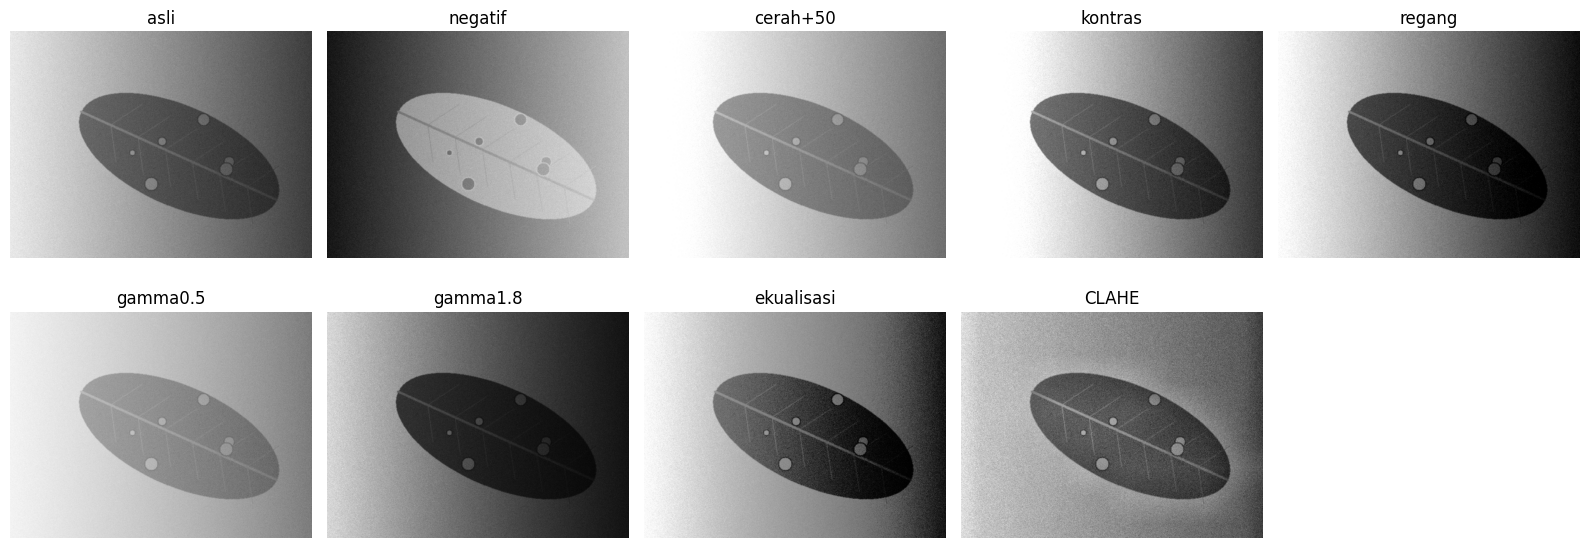

In [4]:
nama = "teh_045.png"
img = baca(f"../data/sintetis/citra/{nama}")
md_ = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0); mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
def gamma_lut(g):
    return np.array([255 * (i / 255) ** g for i in range(256)]).clip(0, 255).astype(np.uint8)
rmin, rmax = np.percentile(gray, (2, 98)); print("persentil 2 dan 98:", rmin, rmax)
hasil = {
 "asli": gray, "negatif": 255 - gray, "cerah+50": cv2.add(gray, 50),
 "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
 "regang": np.clip((gray.astype(float) - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
 "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)), "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
 "ekualisasi": cv2.equalizeHist(gray), "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)}
parameter = {"asli": "-", "negatif": "255 - r", "cerah+50": "+50", "kontras": "alpha 1,5; beta -40",
             "regang": "persentil 2-98", "gamma0.5": "gamma 0,5", "gamma1.8": "gamma 1,8", "ekualisasi": "global", "CLAHE": "clip 2; tile 8"}
rows = []
for nm, c in hasil.items():
    rows.append([nm, parameter[nm], round(kontras_bercak(c, md_, mb), 2), round(float(c.std()), 1)])
tabel10 = pd.DataFrame(rows, columns=["Metode", "Parameter", "KB", "Simpangan baku"])
print(tabel10.to_string(index=False)); tabel10.to_csv("../hasil/b3_tabel10.csv", index=False)
# Gambar 4: citra dan histogram sebelum/sesudah
pilih = ["asli", "ekualisasi", "CLAHE"]
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, nm in enumerate(pilih):
    ax[0, j].imshow(hasil[nm], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(nm); ax[0, j].axis("off")
    ax[1, j].hist(hasil[nm].ravel(), bins=256, range=(0, 256)); ax[1, j].set_xlabel("Intensitas"); ax[1, j].set_ylabel("Jumlah piksel")
plt.tight_layout(); plt.savefig("../hasil/b3_gambar4.png"); plt.show()
# semua metode berdampingan
tampil(list(hasil.values()), list(hasil.keys()), baris=2, ukuran=(16, 6)); plt.savefig("../hasil/b3_semua_metode.png"); plt.show()

**Kolom "Pengamatan visual" Tabel 10:** isi sendiri dengan melihat gambar `b3_semua_metode.png` dan `b3_gambar4.png` (mis. apakah sisi teduh menjadi terlihat, apakah derau membesar, apakah bercak lebih jelas). Pengamatan visual harus berasal dari penglihatanmu sendiri, bukan dari saya.

### Langkah 3.4 Parameter CLAHE dan citra warna (Kode 3.3)

clip tile  KB
 1.0   4  1.91
 1.0   8  1.68
 1.0  16  1.69
 2.0   4  1.94
 2.0   8  1.71
 2.0  16  1.68
 4.0   4  1.89
 4.0   8  1.58
 4.0  16  1.52


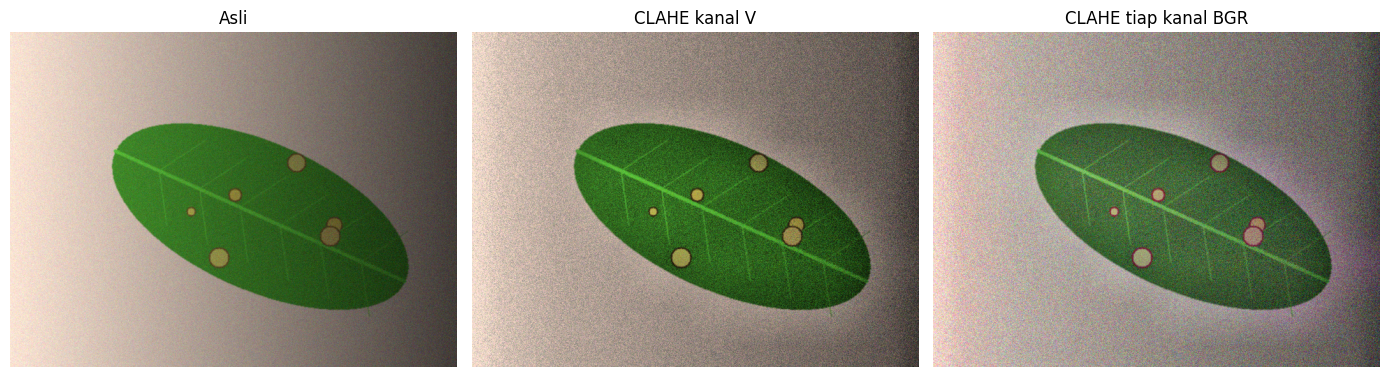

via V    rerata geser Hue di daun = 0.03 | KB R = 5.56 | KB H = 5.10
via BGR  rerata geser Hue di daun = 12.26 | KB R = 3.45 | KB H = 0.31
asli: KB R = 4.32 | KB H = 5.09


In [5]:
print("clip tile  KB")
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"{clip:4.1f} {tile:3d}  {kontras_bercak(c, md_, mb):.2f}")
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2]); via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]); plt.savefig("../hasil/b3_clahe_warna.png"); plt.show()
# bukti kuantitatif: pergeseran Hue di area daun dan KB kanal R/H
H0 = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float)
for nm, o in [("via V", via_v), ("via BGR", via_bgr)]:
    ho = cv2.cvtColor(o, cv2.COLOR_BGR2HSV)[:, :, 0].astype(float); dlt = np.abs(ho - H0); dlt = np.minimum(dlt, 180 - dlt)
    print(f"{nm:8s} rerata geser Hue di daun = {dlt[md_>0].mean():.2f} | KB R = {kontras_bercak(o[:,:,2], md_, mb):.2f} | KB H = {kontras_bercak(cv2.cvtColor(o, cv2.COLOR_BGR2HSV)[:,:,0], md_, mb):.2f}")
print("asli: KB R =", round(kontras_bercak(img[:, :, 2], md_, mb), 2), "| KB H =", round(kontras_bercak(H0.astype(np.uint8), md_, mb), 2))

### Langkah 3.5 Satu perbaikan per kondisi, diterapkan pada kelas berat dan ringan

       kondisi   citra  kelas             perbaikan  KB_sebelum  KB_sesudah
         gelap teh_042  berat regang persentil 2-98        3.41        3.71
         gelap teh_022 ringan regang persentil 2-98        2.26        2.53
        terang teh_043  berat             gamma 1,8        4.78        5.22
        terang teh_023 ringan             gamma 1,8        1.67        1.83
kontras_rendah teh_044  berat regang persentil 2-98        1.89        2.02
kontras_rendah teh_024 ringan regang persentil 2-98        1.64        1.75
      bayangan teh_045  berat  CLAHE clip 2, tile 8        1.11        1.71
      bayangan teh_025 ringan  CLAHE clip 2, tile 8        1.69        1.76


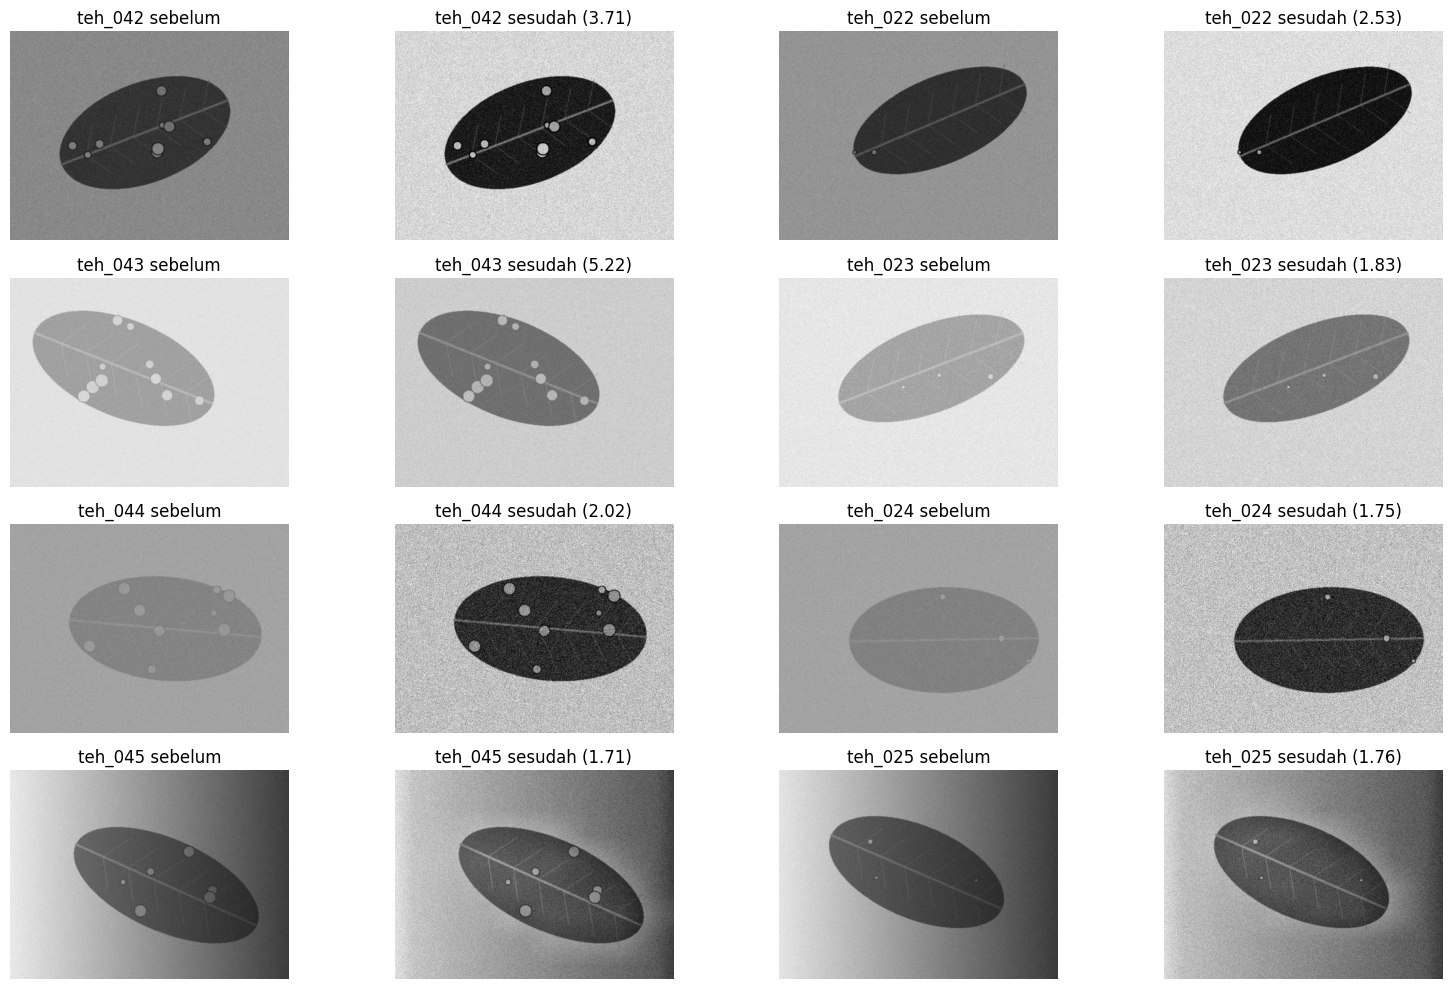

In [6]:
def regang(g):
    a, b_ = np.percentile(g, (2, 98)); return np.clip((g.astype(float) - a) / (b_ - a) * 255, 0, 255).astype(np.uint8)
perbaikan = {
 "gelap":          ("regang persentil 2-98", regang),
 "terang":         ("gamma 1,8",            lambda g: cv2.LUT(g, gamma_lut(1.8))),
 "kontras_rendah": ("regang persentil 2-98", regang),
 "bayangan":       ("CLAHE clip 2, tile 8", lambda g: cv2.createCLAHE(2.0, (8, 8)).apply(g)),
}
pasangan = {"gelap": ("teh_042", "teh_022"), "terang": ("teh_043", "teh_023"), "kontras_rendah": ("teh_044", "teh_024"), "bayangan": ("teh_045", "teh_025")}
rows, daftar, judul = [], [], []
for kond, (nm_b, nm_r) in pasangan.items():
    nm_perb, fn = perbaikan[kond]
    for kelas, nm in [("berat", nm_b), ("ringan", nm_r)]:
        g_ = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}.png"), cv2.COLOR_BGR2GRAY); o = fn(g_)
        a = cv2.imread(f"../data/sintetis/mask_daun/{nm}.png", 0); b_ = cv2.imread(f"../data/sintetis/mask_bercak/{nm}.png", 0)
        k0, k1 = kontras_bercak(g_, a, b_), kontras_bercak(o, a, b_)
        rows.append([kond, nm, kelas, nm_perb, round(k0, 2), round(k1, 2)])
        daftar += [g_, o]; judul += [f"{nm} sebelum", f"{nm} sesudah ({k1:.2f})"]
tabel35 = pd.DataFrame(rows, columns=["kondisi", "citra", "kelas", "perbaikan", "KB_sebelum", "KB_sesudah"])
print(tabel35.to_string(index=False)); tabel35.to_csv("../hasil/b3_tabel_langkah35.csv", index=False)
tampil(daftar, judul, baris=4, ukuran=(16, 10)); plt.savefig("../hasil/b3_sebelum_sesudah.png"); plt.show()

### Jawaban Pertanyaan Analisis Bagian 3

**P3.1 Nilai 3 dan 4 sama setelah ekualisasi.** Pada hitung manual, 3 dan 4 sama-sama dipetakan ke 7. Dua tingkat intensitas yang tadinya berbeda kini identik, sehingga perbedaan itu **tidak dapat dipulihkan** lagi (informasi hilang; 4 level asli menjadi 3 level hasil: 1, 4, 7). Ekualisasi hanya memetakan ulang nilai yang sudah ada dengan fungsi tak menurun; ia merenggangkan jarak antar-level yang padat, tetapi tidak menambah detail baru dan dapat menggabungkan level yang jarang. Karena itu tampilan menjadi lebih kontras, bukan lebih kaya informasi.

**P3.2 Ekualisasi global vs CLAHE pada citra bayangan.** Pada teh_045 histogram berbentuk dua puncak (sisi teduh gelap dan sisi terang) dengan simpangan baku 58,4. Ekualisasi global memakai satu fungsi CDF untuk seluruh citra, sehingga ia meregangkan jarak antara dua puncak itu (perbedaan teduh-terang) dan memampatkan rentang di dalam tiap sisi, tempat daun dan bercak berada. Hasilnya KB turun dari 1,11 menjadi 0,90. CLAHE memperbaiki per blok 8 x 8 sehingga tiap area dinormalkan menurut kondisi lokalnya, dan clip limit menahan penguatan derau; KB naik menjadi 1,71. Ini sama dengan kasus kebun teh pada slide P3: sebagian daun teduh dan sebagian terik, sehingga perbaikan harus lokal.

**P3.3 Persentil vs min-maks.** Peregangan min-maks gagal jika ada satu atau beberapa piksel ekstrem (derau, pantulan). Contoh: bila hampir semua piksel bernilai 50 sampai 60 tetapi ada satu piksel derau 0 dan satu piksel 255, maka rmin = 0 dan rmax = 255, sehingga $s = (60-0)/(255-0)\times 255 = 60$: tidak ada peregangan sama sekali. Persentil 2 dan 98 mengabaikan 2% piksel ekstrem di tiap ujung, sehingga rentang efektif (pada teh_045: 51 sampai 232) mencerminkan mayoritas piksel.

**P3.4 CLAHE di kanal V, bukan di tiap kanal BGR.** CLAHE per kanal mengubah rasio antar-kanal secara berbeda di tiap blok, sehingga warna bergeser (warna palsu). Buktinya pada Kode 3.3 (teh_045): rerata pergeseran Hue di area daun hanya **0,03** jika via V, tetapi **12,26** jika via BGR (skala Hue 0 sampai 179). KB kanal H via V = 5,10, sedangkan via BGR anjlok menjadi 0,31; KB kanal R via V = 5,56 vs via BGR = 3,45. CLAHE pada V hanya mengubah kecerahan dan mempertahankan Hue dan Saturasi.

**P3.5 Satu pengaturan atau adaptif?** Satu pengaturan tidak cukup. Pada Bagian 5 (kanal R, 40 citra berbercak), CLAHE clip 2 dengan median 3 menaikkan KB untuk gelap (8,99 menjadi 16,79) dan bayangan (4,53 menjadi 7,76) tetapi **menurunkan** KB kondisi terang (6,39 menjadi 6,14), sedangkan tanpa CLAHE KB terang naik menjadi 10,61. Aturan sederhana berbasis statistik histogram citra keabuan: *jika simpangan baku > 50 (bayangan) maka CLAHE clip 2, tile 4; jika rerata < 140 dan simpangan baku < 40 (gelap) maka CLAHE clip 1; selain itu tanpa CLAHE.* Aturan ini menghasilkan rerata KB 11,38, lebih tinggi daripada pengaturan tetap clip 1 (10,47) dan tanpa CLAHE (10,85). Perhatikan juga hasil Langkah 3.5: mencerahkan citra gelap dengan gamma < 1 justru menurunkan KB (teh_042: 3,41 menjadi 2,83), sebab KB mengukur keterpisahan relatif terhadap variasi daun, bukan kecerahan yang enak dilihat; jadi "tampak lebih indah" tidak sama dengan "bercak lebih mudah dipisahkan". Catatan: ambang tersebut dipilih dari data sintetis yang sama, jadi harus diuji ulang pada foto nyata.

**P3.6 Perbaikan berlebihan.** Contoh: CLAHE dengan clip limit besar (mis. 4) dan tile kecil pada daun sehat memperkuat derau dan tulang daun menjadi bintik atau garis terang yang mirip bercak; gamma yang terlalu kecil (0,5) membuat daun sehat tampak pucat sehingga mengaburkan batas dengan bercak. Pencegahan: batasi clip limit (≤ 2), pilih parameter berdasarkan bukti (KB dan simpangan baku daun sehat), jalankan **uji bercak palsu pada kelas sehat** (Langkah 5.3), dan simpan parameter di JSON agar dapat diaudit.